# TP 2 : Simulation Multi-Agent avec Mesa 3
## Sujet : Formation de l'opinion publique

Dans ce TP, nous allons utiliser **Mesa 3**, le framework Python pour la modélisation basée sur les agents. 

### Rappel de la syntaxe Mesa 3 :
Par rapport aux anciennes versions, Mesa 3 apporte des simplifications majeures :
* **Gestion des agents :** Les agents s'enregistrent automatiquement dans le modèle lors de l'appel à `super().__init__(model)`.
* **Activation (Scheduler) :** L'ancien module `time` (avec `RandomActivation`) est remplacé. On utilise désormais l'attribut `self.agents` (un objet `AgentSet`). Pour activer tous les agents dans un ordre aléatoire, on appelle simplement `self.agents.shuffle_do("step")` dans la méthode `step()` du modèle.
* **Espace :** Les agents sont placés dans une grille (ex: `mesa.space.MultiGrid`). Les interactions spatiales se font via les coordonnées des agents.
* **Collecte de données :** Le `DataCollector` permet toujours d'extraire les variables du modèle et des agents à chaque "tick" (pas de temps) pour l'analyse via `pandas`.

## 1. Description du Modèle (Protocole ODD)

### Phénomène à modéliser
Dans les sociétés modernes, l'opinion publique se forme par les interactions entre individus. À l'aide d'un SMA, nous étudions comment ces interactions locales peuvent produire un consensus, une polarisation ou des groupes d'opinion.

### Overview (Vue d'ensemble)
* **Objectif :** Simuler l'évolution des opinions individuelles dans une population afin d'étudier l'émergence de consensus, de polarisation ou de groupes d'opinion.
* **Entités :** Les agents représentent des individus.
* **Variables d'état :** L'opinion $o_i \in [0,1]$ (0 = totalement contre, 0.5 = neutre, 1 = totalement pour).
* **Processus :** À chaque tick, un agent observe les opinions de ses voisins $\mathcal{N}_i$, calcule leur moyenne $\bar{o}_{\mathcal{N}_i}^{\,t}$, et ajuste son opinion : 
  $o_i^{t+1}=o_i^t+\alpha\left(\bar{o}_{\mathcal{N}_i}^{\,t}-o_i^t\right)$ avec $\alpha\in[0,1]$.

### Design Concepts
* **Émergence :** Consensus, polarisation ou clusters émergent sans coordination centrale.
* **Interaction :** Chaque agent s'ajuste en fonction de l'opinion de ses voisins.
* **Adaptation / Stochasticité :** L'opinion initiale est aléatoire. Les agents s'adaptent sous influence sociale.
* **Observation :** Opinion moyenne, variance (dispersion), nombre de clusters, vitesse de convergence.

### Details
* **Initialisation :** $N$ agents sur une grille. Initialisation aléatoire de $o_i$ et définition de l'influence $\alpha$.
* **Données d'entrée :** $N$ (population), taille de la grille, paramètre d'influence $\alpha$, durée de la simulation.

In [1]:
# Importation des bibliothèques nécessaires
import mesa
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Configuration de l'affichage des graphiques
%matplotlib inline

Could not import SolaraViz. If you need it, install with 'pip install --pre mesa[viz]'


C:\Users\wawah\Desktop\tp2\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Implémentation de l'Agent

L'agent `CitizenAgent` possède une variable d'état `opinion`. À chaque itération (`step`), il récupère la liste de ses voisins sur la grille, calcule la moyenne de leurs opinions, et rapproche sa propre opinion de cette moyenne proportionnellement à son coefficient d'influence $\alpha$.

In [2]:
class CitizenAgent(mesa.Agent):
    """Un individu ayant une opinion qui évolue selon ses voisins."""
    def __init__(self, model, alpha):
        # Initialisation de l'agent (l'enregistrement dans le modèle est automatique dans Mesa 3)
        super().__init__(model)
        
        # Opinion initiale tirée aléatoirement entre 0 et 1
        self.opinion = self.model.random.random()
        # Niveau d'influence sociale
        self.alpha = alpha

    def step(self):
        # Récupération des voisins (Moore = 8 voisins alentours, sans inclure le centre)
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False)
        
        if len(neighbors) > 0:
            # Calcul de l'opinion moyenne des voisins
            mean_opinion = np.mean([neighbor.opinion for neighbor in neighbors])
            
            # Mise à jour de l'opinion selon la formule mathématique du TD
            self.opinion = self.opinion + self.alpha * (mean_opinion - self.opinion)

## 3. Implémentation du Modèle

Le modèle `OpinionModel` initialise l'espace (une grille `MultiGrid`), peuple cette grille avec nos agents, et gère le déroulement du temps et la collecte des données.

In [3]:
class OpinionModel(mesa.Model):
    """Modèle simulant la formation de l'opinion publique sur une grille."""
    def __init__(self, width, height, alpha=0.2, seed=None):
        super().__init__(seed=seed)
        
        # Espace discret (grille) avec bords communicants (torus=True)
        self.grid = mesa.space.MultiGrid(width, height, torus=True)
        self.alpha = alpha
        
        # Initialisation de la population : on place un agent par case
        for _, (x, y) in self.grid.coord_iter():  # Mesa 3 : (contenu, (x, y))
            agent = CitizenAgent(self, self.alpha)
            self.grid.place_agent(agent, (x, y))
            
        # Mise en place du collecteur de données pour l'observation
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "Opinion Moyenne": lambda m: np.mean([a.opinion for a in m.agents]),
                "Variance (Dispersion)": lambda m: np.var([a.opinion for a in m.agents])
            },
            agent_reporters={
                "Opinion": "opinion"
            }
        )

    def step(self):
        # 1. Collecter les données de l'état actuel
        self.datacollector.collect(self)
        # 2. Activer tous les agents dans un ordre aléatoire (Syntaxe Mesa 3)
        self.agents.shuffle_do("step")

## 4. Exécution de la simulation et Observation

Nous allons maintenant instancier notre modèle, le faire tourner pendant un certain nombre de ticks, et observer l'évolution globale (la moyenne et la dispersion) ainsi que l'évolution individuelle pour identifier l'émergence d'un consensus ou de groupes.

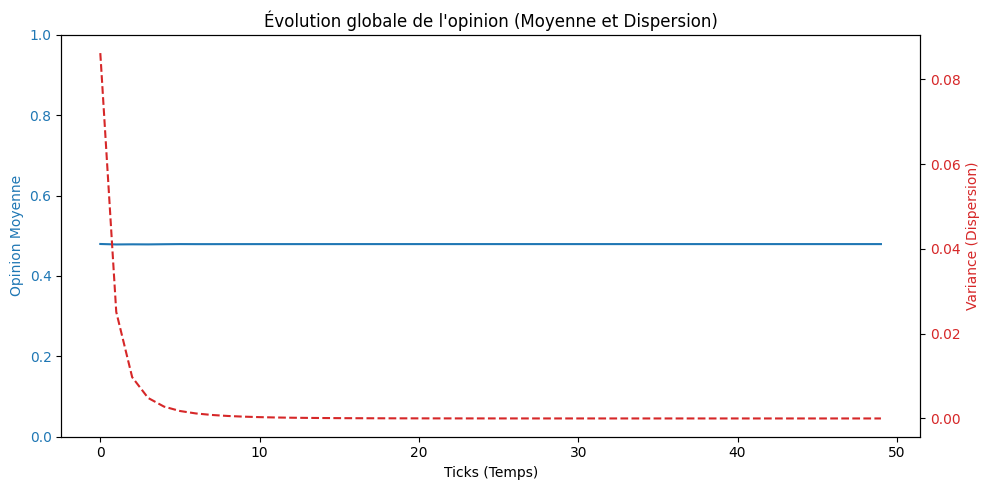

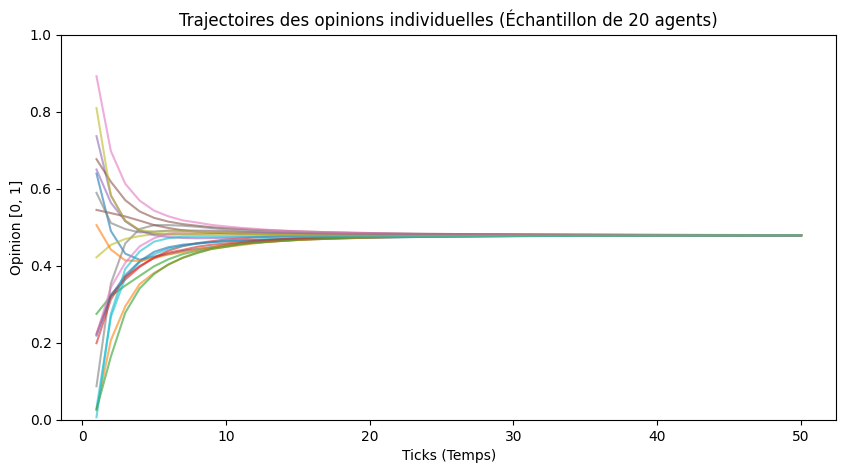

In [4]:
# Paramètres du modèle
WIDTH = 10
HEIGHT = 10
ALPHA = 0.5  # Modifiez alpha pour observer son impact sur la vitesse de convergence
STEPS = 50

# Création et exécution du modèle
model = OpinionModel(width=WIDTH, height=HEIGHT, alpha=ALPHA, seed=42)

for i in range(STEPS):
    model.step()

# Récupération des données collectées
model_data = model.datacollector.get_model_vars_dataframe()
agent_data = model.datacollector.get_agent_vars_dataframe()

# Affichage des résultats globaux (Moyenne et Variance)
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Ticks (Temps)')
ax1.set_ylabel('Opinion Moyenne', color=color)
ax1.plot(model_data.index, model_data['Opinion Moyenne'], color=color, label="Moyenne")
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Variance (Dispersion)', color=color)
ax2.plot(model_data.index, model_data['Variance (Dispersion)'], color=color, linestyle='--', label="Variance")
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Évolution globale de l'opinion (Moyenne et Dispersion)")
fig.tight_layout()
plt.show()

# Affichage des trajectoires individuelles (Polarisation vs Consensus)
# On prend un échantillon de 20 agents pour la lisibilité
agent_opinions = agent_data.unstack(level=1)['Opinion']
sample_agents = agent_opinions.columns[:20]

plt.figure(figsize=(10, 5))
for agent_id in sample_agents:
    plt.plot(agent_opinions.index, agent_opinions[agent_id], alpha=0.6)

plt.title("Trajectoires des opinions individuelles (Échantillon de 20 agents)")
plt.xlabel("Ticks (Temps)")
plt.ylabel("Opinion [0, 1]")
plt.ylim(0, 1)
plt.show()

## 5. Questions d'analyse et de compréhension

**Compréhension théorique (Dynamique des systèmes complexes)**
* Quel est l'impact précis du paramètre d'influence $\alpha$ sur la vitesse de convergence globale ? Que se passe-t-il visuellement sur le graphique si $\alpha$ est très proche de 0, ou à l'inverse, égal à 1 ?
* Dans le modèle actuel, le système finit presque toujours par converger vers un consensus global. Quel mécanisme mathématique de la méthode `step()` (mise à jour de l'opinion) rend la polarisation ou la création de groupes impossible à long terme avec cette configuration exacte ?
* En vous basant sur le protocole ODD, expliquez avec vos propres mots comment la notion d'"émergence" se manifeste dans les graphiques que vous avez générés. 

**Technique et manipulation de Mesa 3**
* Comment l'activation des agents est-elle gérée dans la nouvelle syntaxe de Mesa 3 (`self.agents.shuffle_do("step")`) par rapport aux itérations classiques sur des listes ? Quel est l'intérêt de l'ordre aléatoire ici ?
* Expliquez la différence entre `model_reporters` et `agent_reporters` lors de l'instanciation du `DataCollector`. Pourquoi est-il indispensable d'utiliser les deux pour observer à la fois le consensus et la dispersion ?
* Si un agent se trouve sur le bord de la grille (par exemple en `x=0`), comment le paramètre `torus=True` du `MultiGrid` affecte-t-il la récupération de ses voisins ?

**Ouverture et esprit critique (Pour aller plus loin)**
* Comment modifieriez-vous le code de l'agent pour introduire un "biais de confirmation" (c'est-à-dire qu'un agent n'est influencé par un voisin que si l'écart entre leurs deux opinions est inférieur à un seuil de tolérance $\epsilon$) ? Quel phénomène social émergerait alors ?
* Si nous devions modéliser un véritable réseau social (comme un graphe d'abonnés) plutôt qu'une grille spatiale, quelle structure topologique de Mesa utiliseriez-vous pour modéliser des "influenceurs" très connectés face à des utilisateurs isolés ?

---
# À vous — Expérimentations

Cette partie contient les expériences réalisées pour répondre aux questions de la section 5.
Les réponses rédigées se trouvent dans [`REPONSES.md`](REPONSES.md) ; chaque figure produite ici est
enregistrée dans le dossier `figures/` et reprise dans ce document.

> **Remarque sur l'énoncé.** Avec Mesa 3, `grid.coord_iter()` renvoie des couples `(contenu, (x, y))`.
> La boucle `for _, x, y in self.grid.coord_iter()` de l'énoncé lève donc une `ValueError` ;
> elle a été corrigée en `for _, (x, y) in ...` dans la cellule du modèle ci-dessus.

In [5]:
import os
import sys
import networkx as nx

os.makedirs("figures", exist_ok=True)
plt.rcParams["figure.dpi"] = 110

print("Python  :", sys.version.split()[0])
print("Mesa    :", mesa.__version__)
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("networkx:", nx.__version__)

Python  : 3.10.9
Mesa    : 3.0.3
NumPy   : 2.2.6
pandas  : 2.3.3
networkx: 3.4.2


## 6.0 Modèle paramétrable

Pour les expériences, on généralise légèrement le modèle de l'énoncé (sans changer sa dynamique par défaut) :

* `epsilon` : seuil de tolérance du biais de confirmation (`None` = modèle de l'énoncé) ;
* `torus` : bords communicants ou non ;
* `activation` : `"random"` → `shuffle_do("step")`, `"sequential"` → `do("step")` (ordre fixe).

In [6]:
class CitizenAgentV2(mesa.Agent):
    # Citoyen avec, en option, un biais de confirmation (seuil de tolérance epsilon).
    def __init__(self, model, alpha, epsilon=None):
        super().__init__(model)
        self.opinion = self.model.random.random()
        self.alpha = alpha
        self.epsilon = epsilon

    def step(self):
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False)

        # Biais de confirmation : on n'écoute que les voisins "assez proches" de sa propre opinion
        if self.epsilon is not None:
            neighbors = [n for n in neighbors if abs(n.opinion - self.opinion) < self.epsilon]

        if len(neighbors) > 0:
            mean_opinion = np.mean([n.opinion for n in neighbors])
            self.opinion = self.opinion + self.alpha * (mean_opinion - self.opinion)


class OpinionModelV2(mesa.Model):
    def __init__(self, width=10, height=10, alpha=0.2, epsilon=None,
                 torus=True, activation="random", seed=None):
        super().__init__(seed=seed)
        self.grid = mesa.space.MultiGrid(width, height, torus=torus)
        self.activation = activation

        for _, (x, y) in self.grid.coord_iter():
            self.grid.place_agent(CitizenAgentV2(self, alpha, epsilon), (x, y))

        self.datacollector = mesa.DataCollector(
            model_reporters={
                "Opinion Moyenne": lambda m: np.mean(m.agents.get("opinion")),
                "Variance (Dispersion)": lambda m: np.var(m.agents.get("opinion")),
                "Min": lambda m: np.min(m.agents.get("opinion")),
                "Max": lambda m: np.max(m.agents.get("opinion")),
            },
            agent_reporters={"Opinion": "opinion"},
        )

    def step(self):
        self.datacollector.collect(self)
        if self.activation == "random":
            self.agents.shuffle_do("step")   # ordre aléatoire, re-tiré à chaque tick
        else:
            self.agents.do("step")           # ordre fixe (ordre de création)

    def opinion_grid(self):
        # Opinions sous forme de matrice (pour les cartes de chaleur)
        g = np.zeros((self.grid.width, self.grid.height))
        for a in self.agents:
            g[a.pos] = a.opinion
        return g


def run(steps, **params):
    # Exécute un modèle et renvoie (modèle, données modèle, données agents)
    model = OpinionModelV2(**params)
    for _ in range(steps):
        model.step()
    model.datacollector.collect(model)   # état final
    return (model,
            model.datacollector.get_model_vars_dataframe(),
            model.datacollector.get_agent_vars_dataframe())


def convergence_time(alpha, seed, threshold=1e-4, max_steps=3000, **params):
    # Premier tick où la variance passe sous `threshold` (None si jamais atteint)
    model = OpinionModelV2(alpha=alpha, seed=seed, **params)
    for t in range(1, max_steps + 1):
        model.agents.shuffle_do("step")
        if np.var(model.agents.get("opinion")) < threshold:
            return t
    return None

## 6.1 Impact de $\alpha$ sur la vitesse de convergence

On mesure la variance des opinions au cours du temps pour plusieurs valeurs de $\alpha$ (échelle logarithmique),
puis le **temps de convergence** défini comme le premier tick où la variance passe sous $10^{-4}$
(moyenne sur 5 graines aléatoires, grille 10×10).

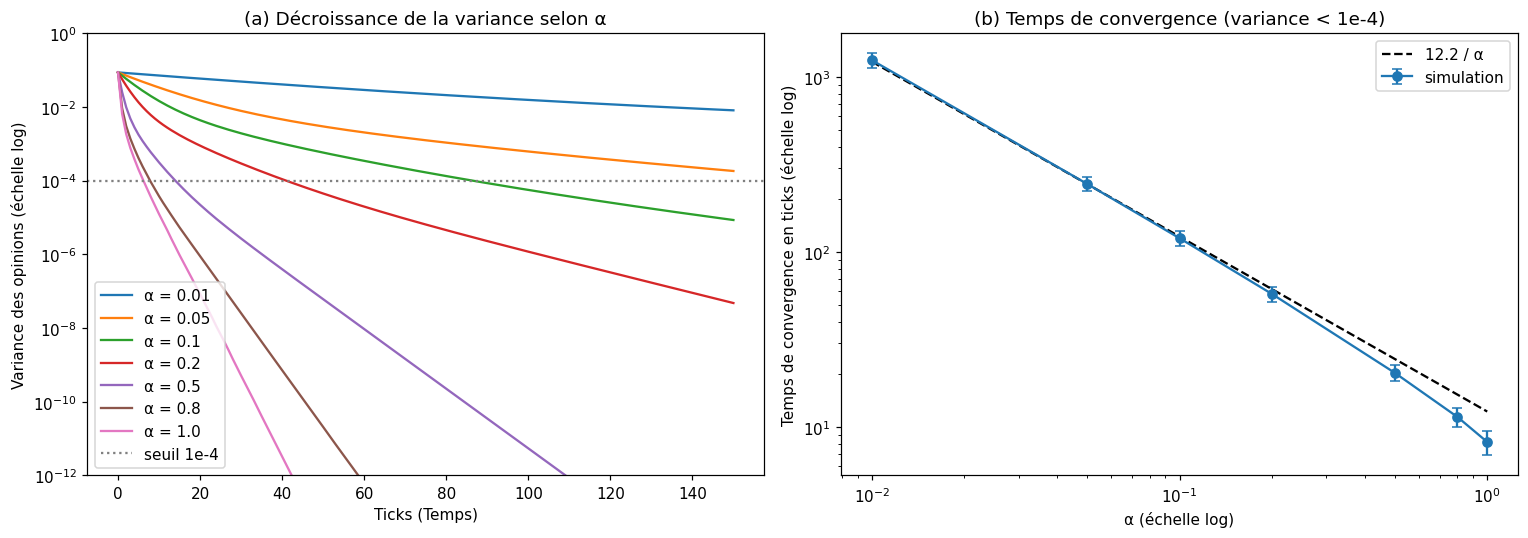

,alpha,t_conv moyen,écart-type,alpha × t_conv
0,0.01,1247.8,117.90,12.48
1,0.05,245.2,22.96,12.26
2,0.10,119.8,11.20,11.98
3,0.20,57.4,5.43,11.48
4,0.50,20.4,2.06,10.20
5,0.80,11.4,1.36,9.12
6,1.00,8.2,1.33,8.20


In [7]:
alphas = [0.01, 0.05, 0.1, 0.2, 0.5, 0.8, 1.0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Variance au cours du temps
for a in alphas:
    _, mdf, _ = run(150, width=10, height=10, alpha=a, seed=42)
    axes[0].semilogy(mdf.index, mdf["Variance (Dispersion)"], label=f"α = {a}")
axes[0].axhline(1e-4, color="grey", linestyle=":", label="seuil 1e-4")
axes[0].set_ylim(1e-12, 1)
axes[0].set_xlabel("Ticks (Temps)")
axes[0].set_ylabel("Variance des opinions (échelle log)")
axes[0].set_title("(a) Décroissance de la variance selon α")
axes[0].legend()

# (b) Temps de convergence moyen sur 5 graines
seeds = [1, 2, 3, 4, 5]
rows = []
for a in alphas:
    times = [convergence_time(a, s) for s in seeds]
    rows.append({"alpha": a, "t_conv moyen": np.mean(times), "écart-type": np.std(times),
                 "alpha × t_conv": a * np.mean(times)})
conv = pd.DataFrame(rows)

axes[1].errorbar(conv["alpha"], conv["t_conv moyen"], yerr=conv["écart-type"], marker="o", capsize=3,
                 label="simulation")
c = conv["alpha × t_conv"].iloc[:3].mean()
axes[1].plot(conv["alpha"], c / conv["alpha"], "k--", label=f"{c:.1f} / α")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("α (échelle log)")
axes[1].set_ylabel("Temps de convergence en ticks (échelle log)")
axes[1].set_title("(b) Temps de convergence (variance < 1e-4)")
axes[1].legend()

fig.tight_layout()
fig.savefig("figures/01_alpha_convergence.png", bbox_inches="tight")
plt.show()

conv.round(2)

### Cas extrêmes : $\alpha = 0$, $\alpha \approx 0$, $\alpha = 1$

Trajectoires individuelles de 20 agents pour quatre valeurs de $\alpha$ (même graine, donc mêmes opinions initiales).

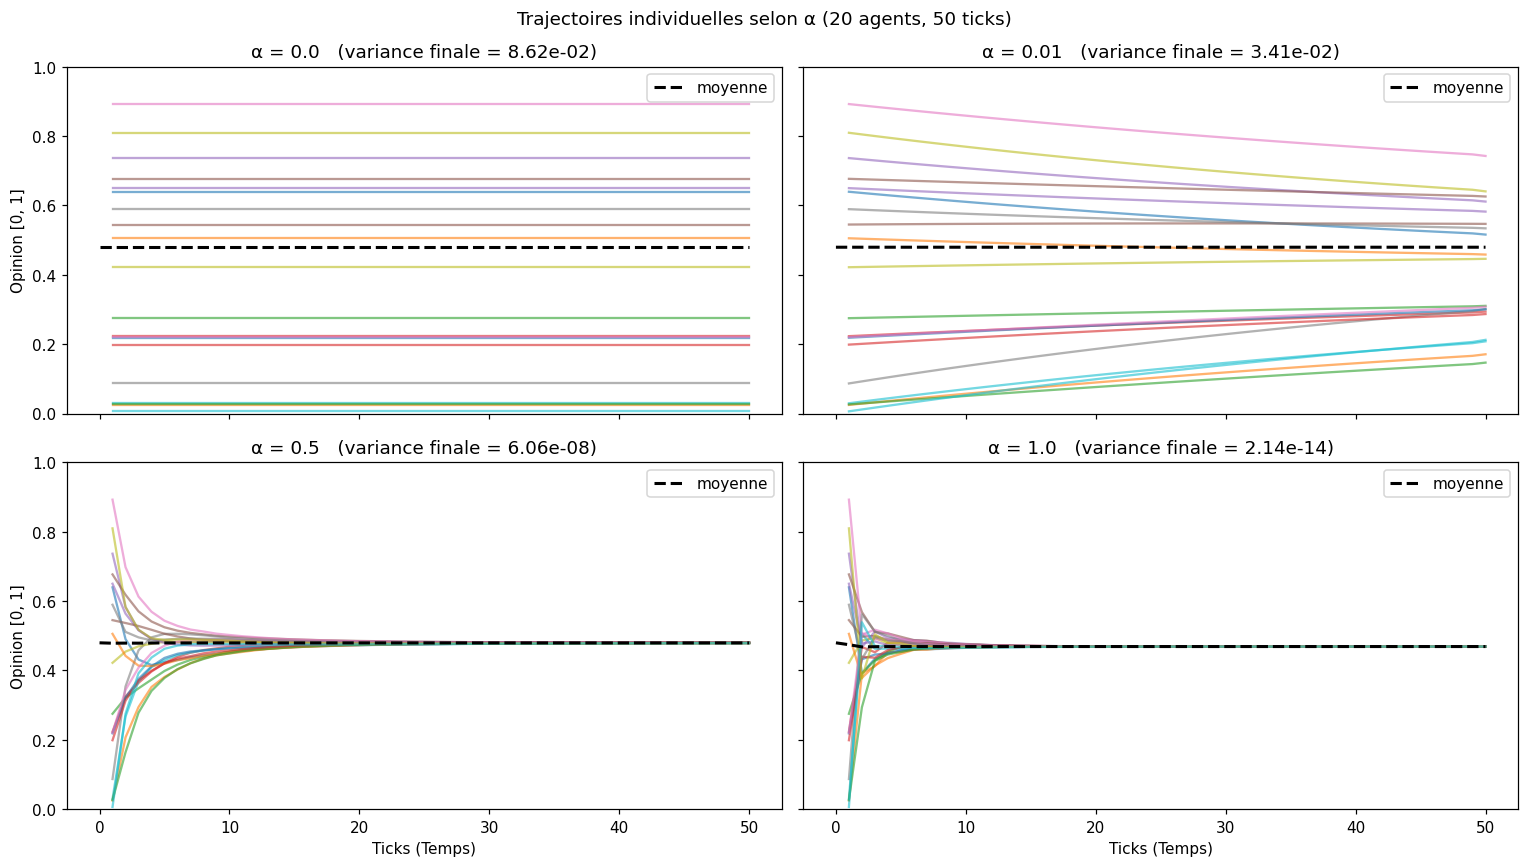

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for ax, a in zip(axes.ravel(), [0.0, 0.01, 0.5, 1.0]):
    _, mdf, adf = run(50, width=10, height=10, alpha=a, seed=42)
    traj = adf.unstack(level=1)["Opinion"]
    for agent_id in traj.columns[:20]:
        ax.plot(traj.index, traj[agent_id], alpha=0.6)
    ax.plot(mdf.index, mdf["Opinion Moyenne"], "k--", linewidth=2, label="moyenne")
    ax.set_title(f"α = {a}   (variance finale = {mdf['Variance (Dispersion)'].iloc[-1]:.2e})")
    ax.set_ylim(0, 1)
    ax.legend(loc="upper right")
for ax in axes[-1]:
    ax.set_xlabel("Ticks (Temps)")
for ax in axes[:, 0]:
    ax.set_ylabel("Opinion [0, 1]")
fig.suptitle("Trajectoires individuelles selon α (20 agents, 50 ticks)")
fig.tight_layout()
fig.savefig("figures/02_alpha_extremes.png", bbox_inches="tight")
plt.show()

## 6.2 Pourquoi le consensus est inévitable : contraction de l'intervalle des opinions

La mise à jour s'écrit $o_i^{t+1} = (1-\alpha)\,o_i^t + \alpha\,\bar{o}_{\mathcal{N}_i}^{\,t}$ : c'est une **combinaison convexe**
de l'opinion de l'agent et de celles de ses voisins. Aucune opinion ne peut donc sortir de l'intervalle
$[\min_j o_j,\ \max_j o_j]$ : le maximum ne peut que décroître, le minimum que croître. On le vérifie numériquement.

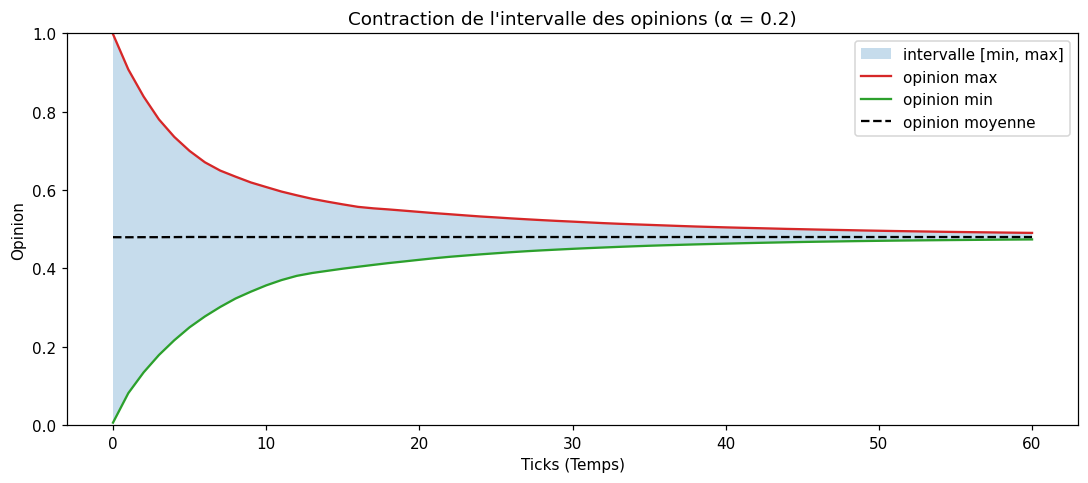

Le max est-il décroissant ? True
Le min est-il croissant   ? True
Moyenne initiale = 0.4796 ; valeur de consensus = 0.4800


In [9]:
_, mdf, _ = run(60, width=10, height=10, alpha=0.2, seed=42)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.fill_between(mdf.index, mdf["Min"], mdf["Max"], alpha=0.25, label="intervalle [min, max]")
ax.plot(mdf.index, mdf["Max"], color="tab:red", label="opinion max")
ax.plot(mdf.index, mdf["Min"], color="tab:green", label="opinion min")
ax.plot(mdf.index, mdf["Opinion Moyenne"], "k--", label="opinion moyenne")
ax.set_ylim(0, 1)
ax.set_xlabel("Ticks (Temps)"); ax.set_ylabel("Opinion")
ax.set_title("Contraction de l'intervalle des opinions (α = 0.2)")
ax.legend()
fig.tight_layout()
fig.savefig("figures/03_contraction_min_max.png", bbox_inches="tight")
plt.show()

print("Le max est-il décroissant ?", bool((mdf["Max"].diff().dropna() <= 1e-12).all()))
print("Le min est-il croissant   ?", bool((mdf["Min"].diff().dropna() >= -1e-12).all()))
print(f"Moyenne initiale = {mdf['Opinion Moyenne'].iloc[0]:.4f} ; valeur de consensus = {mdf['Opinion Moyenne'].iloc[-1]:.4f}")

## 6.3 Émergence : du désordre local au consensus global

Cartes des opinions sur une grille 20×20 à différents ticks. Aucune règle globale n'existe dans le code :
chaque agent ne regarde que ses 8 voisins.

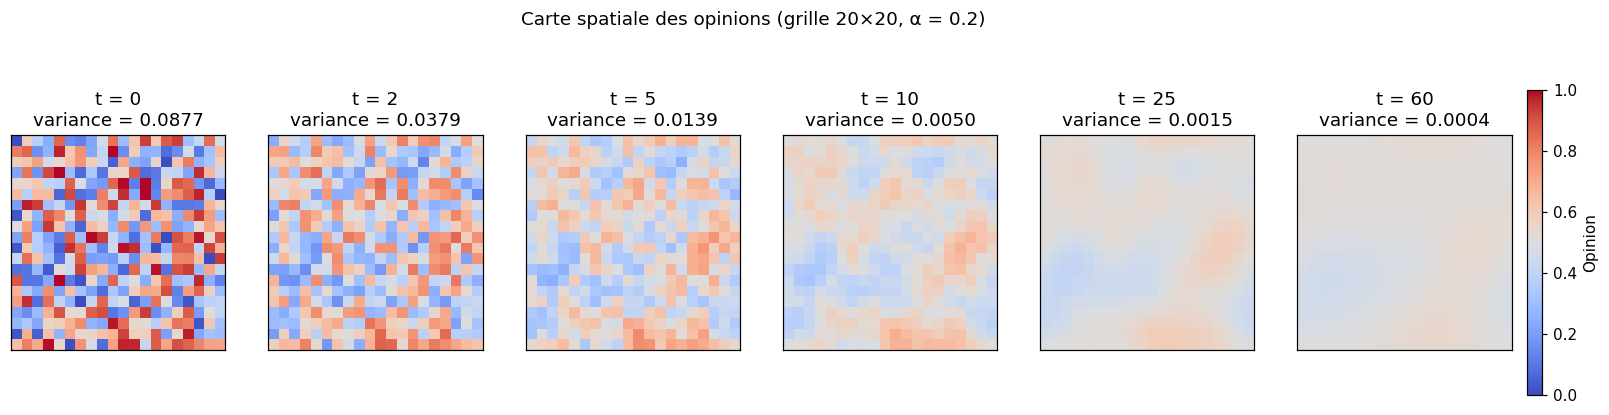

In [10]:
snapshots = [0, 2, 5, 10, 25, 60]
model = OpinionModelV2(width=20, height=20, alpha=0.2, seed=42)

fig, axes = plt.subplots(1, len(snapshots), figsize=(18, 3.6))
t = 0
for ax, target in zip(axes, snapshots):
    while t < target:
        model.step()
        t += 1
    g = model.opinion_grid()
    im = ax.imshow(g.T, cmap="coolwarm", vmin=0, vmax=1, origin="lower")
    ax.set_title(f"t = {target}\nvariance = {g.var():.4f}")
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.012, pad=0.01, label="Opinion")
fig.suptitle("Carte spatiale des opinions (grille 20×20, α = 0.2)", y=1.08)
fig.savefig("figures/04_emergence_heatmaps.png", bbox_inches="tight")
plt.show()

## 6.4 Activation des agents : `AgentSet`, `shuffle_do` et ordre aléatoire

`model.agents` est un `AgentSet`. On illustre quelques opérations, puis on compare l'activation aléatoire
(`shuffle_do`) à l'activation dans un ordre fixe (`do`) avec $\alpha = 1$, cas où l'effet de l'ordre est le plus marqué.

In [11]:
m = OpinionModelV2(width=10, height=10, alpha=0.5, seed=42)
print("Type de model.agents     :", type(m.agents).__name__)
print("Nombre d'agents          :", len(m.agents))
print("3 premières opinions     :", [round(o, 3) for o in m.agents.get("opinion")[:3]])
print("Agents 'pour' (o > 0.5)  :", len(m.agents.select(lambda a: a.opinion > 0.5)))

# Ordre d'activation : on enregistre l'ordre dans lequel les agents sont appelés sur 2 ticks
order = []
m.agents.shuffle_do(lambda a: order.append(a.unique_id))
tick1, order = order[:8], []
m.agents.shuffle_do(lambda a: order.append(a.unique_id))
print("shuffle_do, tick 1 (8 premiers) :", tick1)
print("shuffle_do, tick 2 (8 premiers) :", order[:8])
order = []
m.agents.do(lambda a: order.append(a.unique_id))
print("do (ordre fixe, 8 premiers)     :", order[:8])

Type de model.agents     : AgentSet
Nombre d'agents          : 100
3 premières opinions     : [0.639, 0.025, 0.275]
Agents 'pour' (o > 0.5)  : 50
shuffle_do, tick 1 (8 premiers) : [92, 67, 74, 12, 7, 90, 10, 41]
shuffle_do, tick 2 (8 premiers) : [76, 5, 88, 16, 65, 75, 37, 23]
do (ordre fixe, 8 premiers)     : [1, 2, 3, 4, 5, 6, 7, 8]


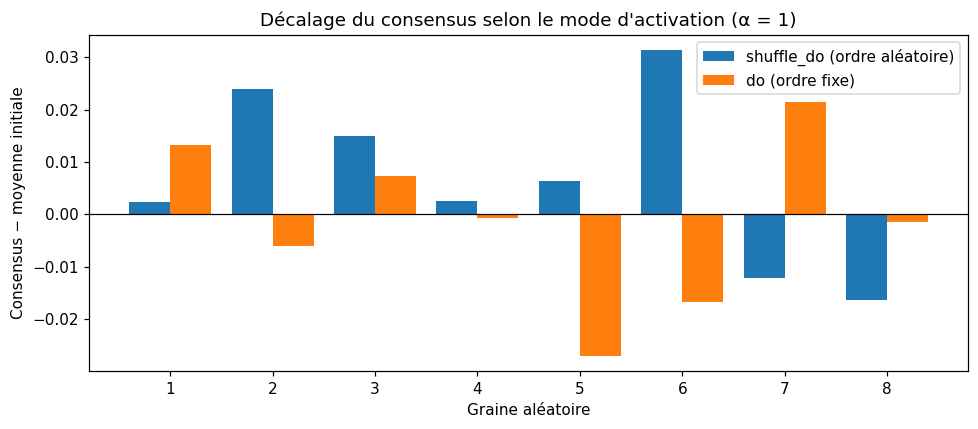

Écart absolu moyen | shuffle_do : 0.0137 | do : 0.0117


,moyenne initiale,consensus (random),consensus (sequential),écart random,écart sequential
graine,,,,,
1,0.5124,0.5148,0.5255,0.0024,0.0132
2,0.5527,0.5766,0.5466,0.0239,-0.0061
3,0.5411,0.5561,0.5485,0.0150,0.0074
4,0.4819,0.4844,0.4813,0.0025,-0.0006
5,0.4973,0.5036,0.4703,0.0063,-0.0270
6,0.5120,0.5434,0.4952,0.0314,-0.0168
7,0.4703,0.4582,0.4917,-0.0121,0.0214
8,0.4602,0.4438,0.4587,-0.0164,-0.0015


In [12]:
rows = []
for seed in range(1, 9):
    res = {"graine": seed}
    for act in ["random", "sequential"]:
        _, mdf, _ = run(200, width=10, height=10, alpha=1.0, activation=act, seed=seed)
        res["moyenne initiale"] = mdf["Opinion Moyenne"].iloc[0]
        res[f"consensus ({act})"] = mdf["Opinion Moyenne"].iloc[-1]
    res["écart random"] = res["consensus (random)"] - res["moyenne initiale"]
    res["écart sequential"] = res["consensus (sequential)"] - res["moyenne initiale"]
    rows.append(res)
act_df = pd.DataFrame(rows).set_index("graine")

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(act_df))
ax.bar(x - 0.2, act_df["écart random"], width=0.4, label='shuffle_do (ordre aléatoire)')
ax.bar(x + 0.2, act_df["écart sequential"], width=0.4, label='do (ordre fixe)')
ax.axhline(0, color="k", linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(act_df.index)
ax.set_xlabel("Graine aléatoire"); ax.set_ylabel("Consensus − moyenne initiale")
ax.set_title("Décalage du consensus selon le mode d'activation (α = 1)")
ax.legend()
fig.tight_layout()
fig.savefig("figures/05_activation_order.png", bbox_inches="tight")
plt.show()

print("Écart absolu moyen | shuffle_do :", round(act_df["écart random"].abs().mean(), 4),
      "| do :", round(act_df["écart sequential"].abs().mean(), 4))
act_df.round(4)

## 6.5 `model_reporters` / `agent_reporters`

Forme des deux tableaux renvoyés par le `DataCollector` pour une même simulation.

In [13]:
_, mdf, adf = run(50, width=10, height=10, alpha=0.5, seed=42)
print("model_reporters ->", mdf.shape, "(une ligne par tick, une colonne par indicateur global)")
display(mdf.head(3))
print("agent_reporters ->", adf.shape, "(une ligne par couple (tick, agent) ; index =", list(adf.index.names), ")")
display(adf.head(3))

model_reporters -> (51, 4) (une ligne par tick, une colonne par indicateur global)


,Opinion Moyenne,Variance (Dispersion),Min,Max
0,0.479569,0.086157,0.006499,0.997538
1,0.478436,0.025126,0.163912,0.773259
2,0.478731,0.009732,0.277999,0.675537


agent_reporters -> (5000, 1) (une ligne par couple (tick, agent) ; index = ['Step', 'AgentID'] )


Opinion
Step AgentID          
1    1        0.639427
     2        0.025011
     3        0.275029

## 6.6 Effet de `torus=True` sur le voisinage des bords

torus=True
   voisinage de (0, 0) : 8 cases -> [(0, 1), (0, 9), (1, 0), (1, 1), (1, 9), (9, 0), (9, 1), (9, 9)]
   voisinage de (0, 5) : 8 cases -> [(0, 4), (0, 6), (1, 4), (1, 5), (1, 6), (9, 4), (9, 5), (9, 6)]
   voisinage de (5, 5) : 8 cases -> [(4, 4), (4, 5), (4, 6), (5, 4), (5, 6), (6, 4), (6, 5), (6, 6)]
   répartition du nombre de voisins : {8: 100}
torus=False
   voisinage de (0, 0) : 3 cases -> [(0, 1), (1, 0), (1, 1)]
   voisinage de (0, 5) : 5 cases -> [(0, 4), (0, 6), (1, 4), (1, 5), (1, 6)]
   voisinage de (5, 5) : 8 cases -> [(4, 4), (4, 5), (4, 6), (5, 4), (5, 6), (6, 4), (6, 5), (6, 6)]
   répartition du nombre de voisins : {3: 4, 5: 32, 8: 64}


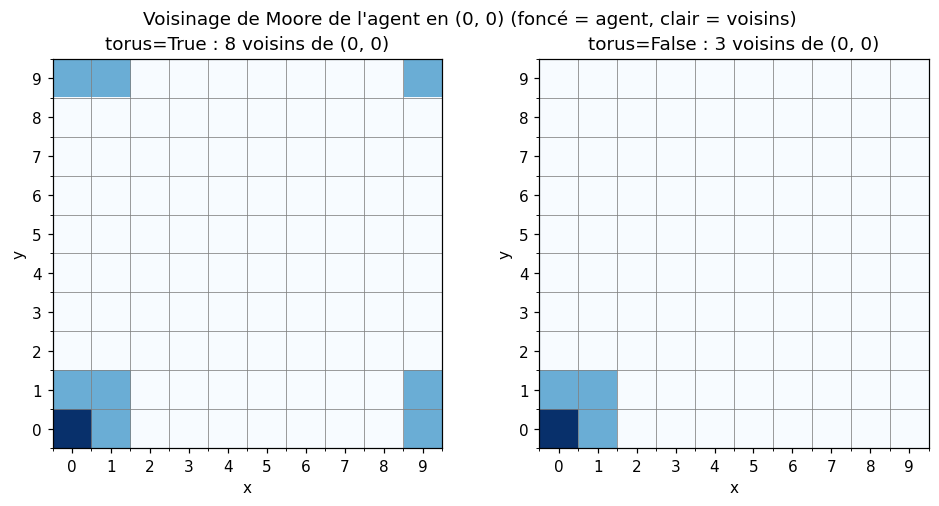

In [14]:
for torus in [True, False]:
    m = OpinionModelV2(width=10, height=10, torus=torus, seed=42)
    print(f"torus={torus}")
    for pos in [(0, 0), (0, 5), (5, 5)]:
        nb = sorted(m.grid.get_neighborhood(pos, moore=True, include_center=False))
        print(f"   voisinage de {pos} : {len(nb)} cases -> {nb}")
    counts = pd.Series([len(m.grid.get_neighbors(a.pos, moore=True, include_center=False)) for a in m.agents])
    print("   répartition du nombre de voisins :", counts.value_counts().sort_index().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, torus in zip(axes, [True, False]):
    m = OpinionModelV2(width=10, height=10, torus=torus, seed=42)
    g = np.zeros((10, 10))
    for p in m.grid.get_neighborhood((0, 0), moore=True, include_center=False):
        g[p] = 1
    g[0, 0] = 2
    ax.imshow(g.T, cmap="Blues", origin="lower")
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xticks(np.arange(-.5, 10), minor=True); ax.set_yticks(np.arange(-.5, 10), minor=True)
    ax.grid(which="minor", color="grey", linewidth=0.5)
    ax.set_title(f"torus={torus} : {int((g == 1).sum())} voisins de (0, 0)")
    ax.set_xlabel("x"); ax.set_ylabel("y")
fig.suptitle("Voisinage de Moore de l'agent en (0, 0) (foncé = agent, clair = voisins)")
fig.tight_layout()
fig.savefig("figures/06_torus_neighbors.png", bbox_inches="tight")
plt.show()

## 6.7 Pour aller plus loin — Biais de confirmation (confiance bornée)

L'agent n'écoute un voisin que si $|o_j - o_i| < \epsilon$ (filtre ajouté dans `CitizenAgentV2.step`).
On compare plusieurs seuils sur une grille 20×20 ($\alpha = 0.5$, 300 ticks).

Pour compter les groupes, on construit le **graphe d'influence final** : deux voisins de grille sont reliés
s'ils s'influencent encore ($|o_i - o_j| < \epsilon$). Chaque composante connexe est un groupe d'opinion.

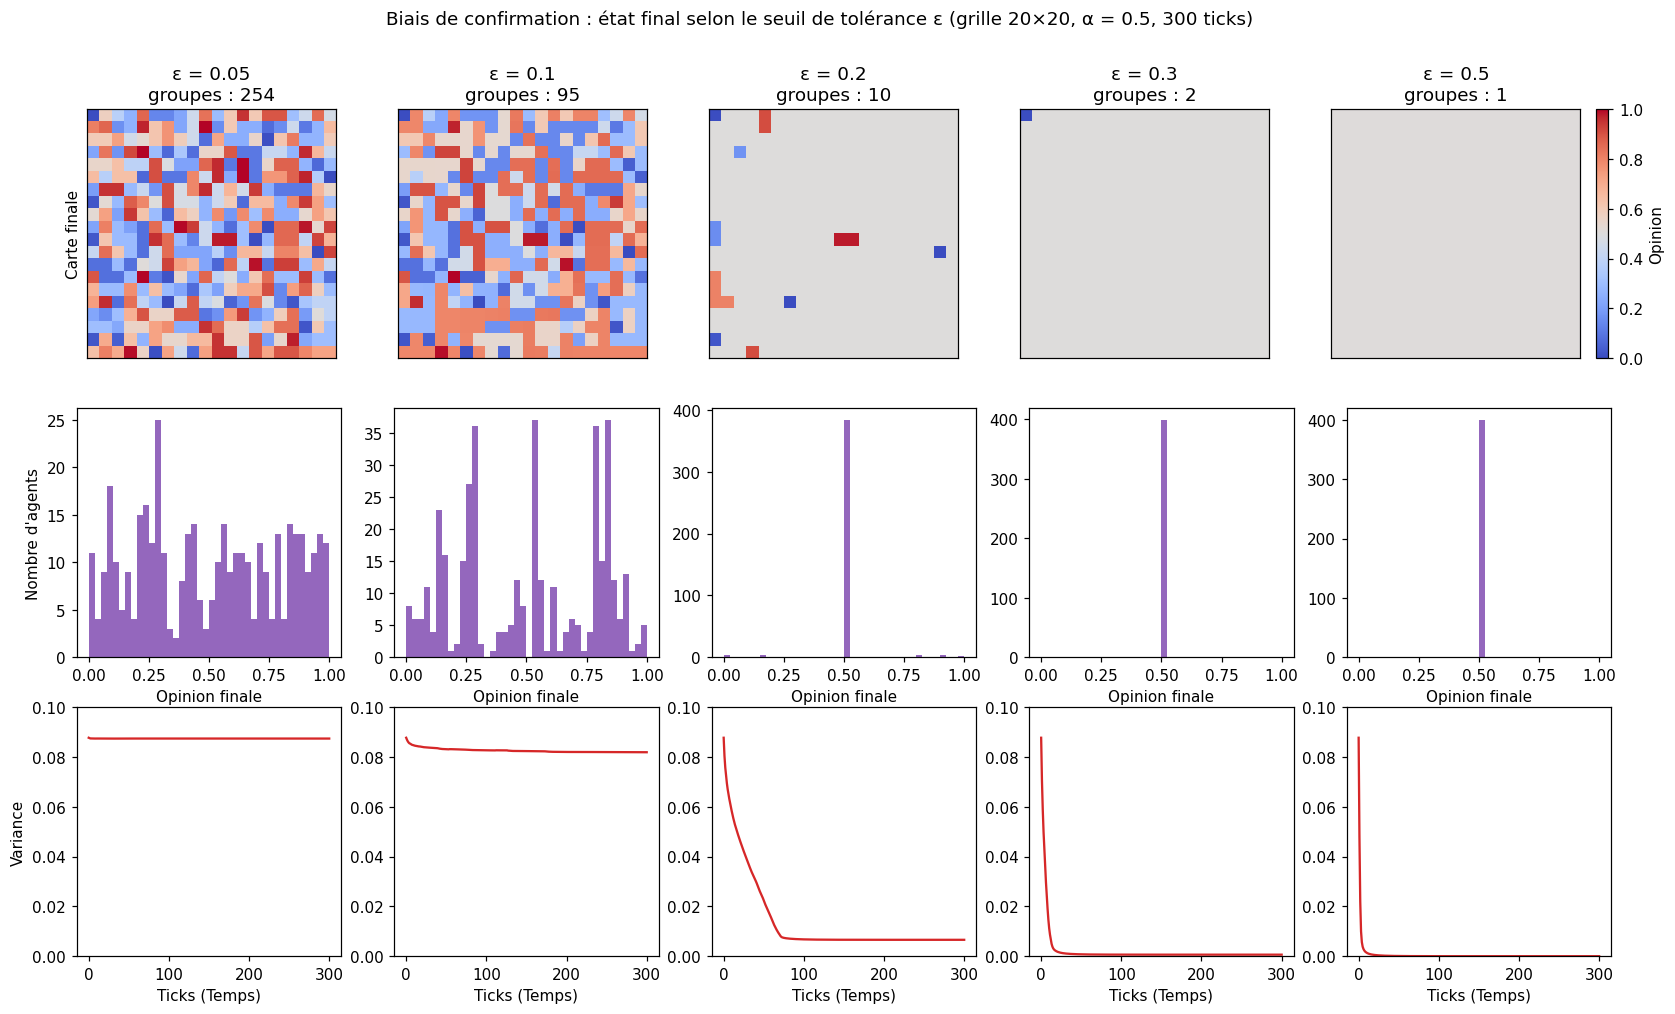

,variance finale,min,max,nb groupes,nb groupes (≥ 5 agents),plus grand groupe,agents isolés
epsilon,,,,,,,
0.05,0.0874,0.0004,0.9993,254,9,11,180
0.10,0.0819,0.0006,0.9975,95,14,96,56
0.20,0.0066,0.0006,0.9767,10,1,384,5
0.30,0.0006,0.0065,0.5037,2,1,399,1
0.50,0.0000,0.5051,0.5052,1,1,400,0


In [15]:
def influence_groups(model, epsilon):
    # Composantes connexes du graphe 'qui influence encore qui' à l'état final
    G = nx.Graph()
    for a in model.agents:
        G.add_node(a.unique_id)
        for n in model.grid.get_neighbors(a.pos, moore=True, include_center=False):
            if abs(n.opinion - a.opinion) < epsilon:
                G.add_edge(a.unique_id, n.unique_id)
    return [len(c) for c in nx.connected_components(G)]


epsilons = [0.05, 0.1, 0.2, 0.3, 0.5]
fig, axes = plt.subplots(3, len(epsilons), figsize=(18, 10))
rows = []
for j, eps in enumerate(epsilons):
    model, mdf, _ = run(300, width=20, height=20, alpha=0.5, epsilon=eps, seed=42)
    ops = np.array(model.agents.get("opinion"))
    sizes = influence_groups(model, eps)
    rows.append({"epsilon": eps, "variance finale": ops.var(), "min": ops.min(), "max": ops.max(),
                 "nb groupes": len(sizes), "nb groupes (≥ 5 agents)": sum(s >= 5 for s in sizes),
                 "plus grand groupe": max(sizes), "agents isolés": sum(s == 1 for s in sizes)})

    im = axes[0, j].imshow(model.opinion_grid().T, cmap="coolwarm", vmin=0, vmax=1, origin="lower")
    axes[0, j].set_title(f"ε = {eps}\ngroupes : {len(sizes)}")
    axes[0, j].set_xticks([]); axes[0, j].set_yticks([])

    axes[1, j].hist(ops, bins=40, range=(0, 1), color="tab:purple")
    axes[1, j].set_xlabel("Opinion finale")

    axes[2, j].plot(mdf.index, mdf["Variance (Dispersion)"], color="tab:red")
    axes[2, j].set_ylim(0, 0.1)
    axes[2, j].set_xlabel("Ticks (Temps)")
axes[0, 0].set_ylabel("Carte finale")
axes[1, 0].set_ylabel("Nombre d'agents")
axes[2, 0].set_ylabel("Variance")
fig.colorbar(im, ax=axes[0, :], fraction=0.01, pad=0.01, label="Opinion")
fig.suptitle("Biais de confirmation : état final selon le seuil de tolérance ε (grille 20×20, α = 0.5, 300 ticks)", y=0.97)
fig.savefig("figures/07_biais_confirmation.png", bbox_inches="tight")
plt.show()

pd.DataFrame(rows).set_index("epsilon").round(4)

## 6.8 Pour aller plus loin — Réseau social avec influenceurs (`NetworkGrid`)

On remplace la grille par un graphe **sans échelle** de Barabási–Albert (attachement préférentiel) placé dans un
`mesa.space.NetworkGrid` : quelques nœuds très connectés (« influenceurs ») et une majorité de nœuds peu connectés.

Pour mesurer le poids d'un influenceur, on rend **un seul** agent « têtu » (opinion fixée à 1, il ne se met jamais à jour)
et on compare deux scénarios : l'agent têtu est le hub le plus connecté, ou un utilisateur périphérique (degré minimal).

In [16]:
class NetworkCitizen(mesa.Agent):
    def __init__(self, model, alpha, opinion=None, stubborn=False):
        super().__init__(model)
        self.opinion = self.model.random.random() if opinion is None else opinion
        self.alpha = alpha
        self.stubborn = stubborn      # un agent têtu diffuse son opinion sans jamais en changer

    def step(self):
        if self.stubborn:
            return
        neighbors = self.model.grid.get_neighbors(self.pos, include_center=False)
        if len(neighbors) > 0:
            mean_opinion = np.mean([n.opinion for n in neighbors])
            self.opinion = self.opinion + self.alpha * (mean_opinion - self.opinion)


class NetworkOpinionModel(mesa.Model):
    def __init__(self, n=200, m=2, alpha=0.5, stubborn="none", seed=None):
        super().__init__(seed=seed)
        self.G = nx.barabasi_albert_graph(n, m, seed=seed)
        self.grid = mesa.space.NetworkGrid(self.G)

        degrees = dict(self.G.degree)
        self.hub = max(degrees, key=degrees.get)
        self.peripheral = min(degrees, key=degrees.get)
        target = {"none": None, "hub": self.hub, "peripheral": self.peripheral}[stubborn]

        for node in self.G.nodes:
            if node == target:
                agent = NetworkCitizen(self, alpha, opinion=1.0, stubborn=True)
            else:
                agent = NetworkCitizen(self, alpha)
            self.grid.place_agent(agent, node)

        self.datacollector = mesa.DataCollector(model_reporters={
            "Opinion Moyenne": lambda m: np.mean(m.agents.get("opinion")),
            "Variance (Dispersion)": lambda m: np.var(m.agents.get("opinion")),
        })

    def step(self):
        self.datacollector.collect(self)
        self.agents.shuffle_do("step")


net = NetworkOpinionModel(seed=42)
deg = np.array([d for _, d in net.G.degree])
print(f"{net.G.number_of_nodes()} nœuds, {net.G.number_of_edges()} arêtes")
print(f"Degré : min = {deg.min()}, médiane = {np.median(deg):.0f}, moyenne = {deg.mean():.2f}, max = {deg.max()}")
print(f"Hub = nœud {net.hub} (degré {deg[net.hub]}) ; périphérique = nœud {net.peripheral} (degré {deg[net.peripheral]})")
print(f"Les 10 nœuds les plus connectés (5 %) portent {np.sort(deg)[-10:].sum() / deg.sum():.0%} des extrémités d'arêtes")

200 nœuds, 396 arêtes
Degré : min = 2, médiane = 2, moyenne = 3.96, max = 45
Hub = nœud 0 (degré 45) ; périphérique = nœud 23 (degré 2)
Les 10 nœuds les plus connectés (5 %) portent 26% des extrémités d'arêtes


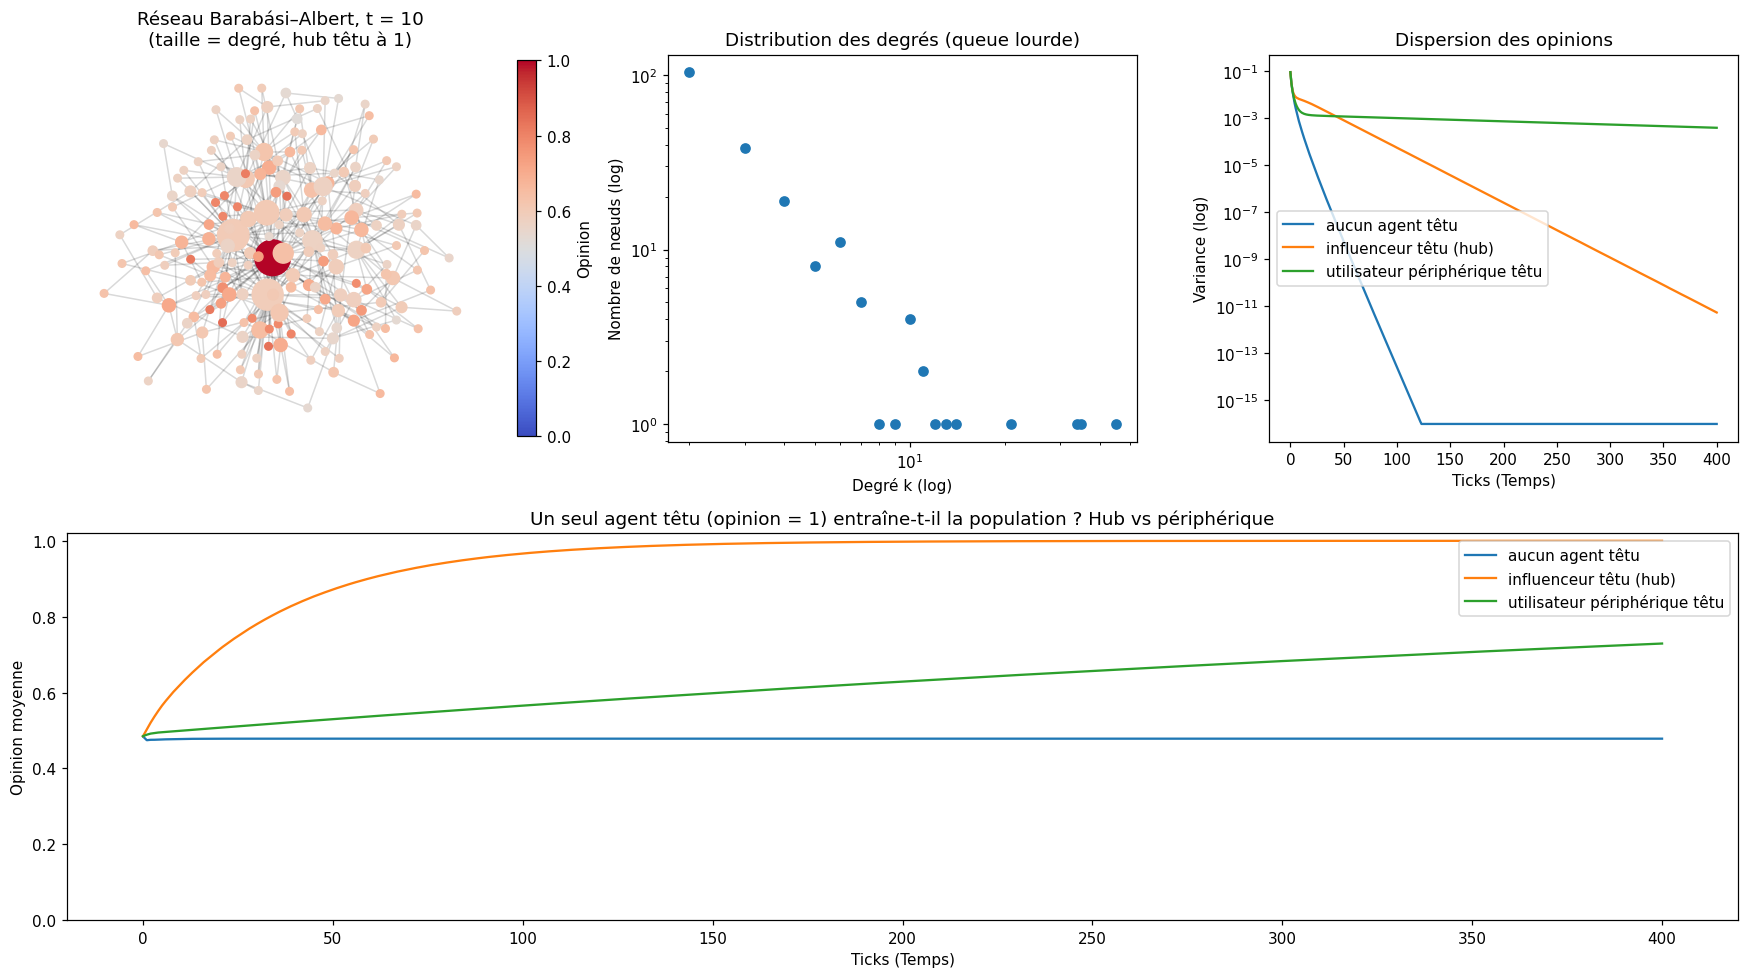

,moyenne à t=0,moyenne à t=10,moyenne à t=50,moyenne à t=100,moyenne à t=400,ticks pour moyenne ≥ 0.9
aucun agent têtu,0.4842,0.4777,0.4785,0.4785,0.4785,NaN
influenceur têtu (hub),0.4850,0.6233,0.8717,0.9665,1.0000,60.0
utilisateur périphérique têtu,0.4850,0.4995,0.5299,0.5656,0.7292,NaN


In [17]:
STEPS_NET = 400
results = {}
for scenario in ["none", "hub", "peripheral"]:
    model = NetworkOpinionModel(stubborn=scenario, seed=42)
    for _ in range(STEPS_NET):
        model.step()
    model.datacollector.collect(model)
    results[scenario] = (model, model.datacollector.get_model_vars_dataframe())

labels = {"none": "aucun agent têtu", "hub": "influenceur têtu (hub)", "peripheral": "utilisateur périphérique têtu"}

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 3)

# Topologie, colorée par l'opinion après 10 ticks du scénario "hub"
ax = fig.add_subplot(gs[0, 0])
snap = NetworkOpinionModel(stubborn="hub", seed=42)
for _ in range(10):
    snap.step()
pos = nx.spring_layout(snap.G, seed=1)
node_op = [snap.grid.get_cell_list_contents([n])[0].opinion for n in snap.G.nodes]
nx.draw_networkx_edges(snap.G, pos, ax=ax, alpha=0.15)
sc = nx.draw_networkx_nodes(snap.G, pos, ax=ax, node_color=node_op, cmap="coolwarm", vmin=0, vmax=1,
                            node_size=[12 * d for _, d in snap.G.degree])
fig.colorbar(sc, ax=ax, fraction=0.04, label="Opinion")
ax.set_title("Réseau Barabási–Albert, t = 10\n(taille = degré, hub têtu à 1)")
ax.axis("off")

# Distribution des degrés
ax = fig.add_subplot(gs[0, 1])
vals, counts = np.unique(deg, return_counts=True)
ax.loglog(vals, counts, "o")
ax.set_xlabel("Degré k (log)"); ax.set_ylabel("Nombre de nœuds (log)")
ax.set_title("Distribution des degrés (queue lourde)")

# Variance
ax = fig.add_subplot(gs[0, 2])
for sc_name, (_, mdf) in results.items():
    ax.semilogy(mdf.index, mdf["Variance (Dispersion)"].clip(lower=1e-16), label=labels[sc_name])
ax.set_xlabel("Ticks (Temps)"); ax.set_ylabel("Variance (log)")
ax.set_title("Dispersion des opinions")
ax.legend()

# Opinion moyenne
ax = fig.add_subplot(gs[1, :])
for sc_name, (_, mdf) in results.items():
    ax.plot(mdf.index, mdf["Opinion Moyenne"], label=labels[sc_name])
ax.set_ylim(0, 1.02)
ax.set_xlabel("Ticks (Temps)"); ax.set_ylabel("Opinion moyenne")
ax.set_title("Un seul agent têtu (opinion = 1) entraîne-t-il la population ? Hub vs périphérique")
ax.legend()

fig.tight_layout()
fig.savefig("figures/08_reseau_influenceurs.png", bbox_inches="tight")
plt.show()

summary = pd.DataFrame({labels[k]: {f"moyenne à t={t}": mdf["Opinion Moyenne"].iloc[t] for t in [0, 10, 50, 100, 400]}
                        for k, (_, mdf) in results.items()}).T
def t_reach(mdf, level=0.9):
    hit = mdf.index[mdf["Opinion Moyenne"] >= level]
    return int(hit[0]) if len(hit) else None
summary["ticks pour moyenne ≥ 0.9"] = [t_reach(mdf) for _, mdf in results.values()]
summary.round(4)

---
**Fin du notebook.** Les réponses rédigées aux questions de la section 5, appuyées sur les figures ci-dessus,
sont dans [`REPONSES.md`](REPONSES.md).